# Predictive Maintenance — RUL Prediction

## Goal

Estimate the **Remaining Useful Life (RUL)** of turbofan engines from their operating conditions and sensor measurements.

This is a supervised regression problem with a time-series structure. The important part is not only fitting a model, but also avoiding information leakage between engines and evaluating the model in a way that is closer to the real predictive-maintenance scenario.

The project uses the NASA C-MAPSS turbofan data available on Kaggle and focuses on the **FD001** subset for a controlled portfolio project.


## 1. Imports and setup

Dataset source: Kaggle — **NASA Turbofan / Predictive Maintenance**.

The Kaggle dataset contains multivariate time series for individual engines. FD001 contains 100 training engine trajectories and 100 test trajectories, with one operating condition and one main fault mode. The official task is to predict RUL in cycles for the test engines.


In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub

from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

COLUMN_NAMES = (
    ["unit_number", "time_cycles", "setting_1", "setting_2", "setting_3"]
    + [f"sensor_{i}" for i in range(1, 22)]
)


## 2. Load the Kaggle data

I use `kagglehub` to download the dataset instead of relying on a hard-coded `/kaggle/input/...` path.

The loader searches for the FD001 files automatically, which makes the notebook less dependent on the exact Kaggle folder name.


In [2]:
dataset_path = kagglehub.dataset_download(
    "behrad3d/nasa-cmaps"
)

print("Dataset downloaded to:", dataset_path)

root = Path(dataset_path)

train_candidates = list(root.rglob("train_FD001.txt"))
test_candidates = list(root.rglob("test_FD001.txt"))
rul_candidates = list(root.rglob("RUL_FD001.txt"))

if not train_candidates or not test_candidates or not rul_candidates:
    raise FileNotFoundError(
        "Could not find train_FD001.txt, test_FD001.txt, "
        "and RUL_FD001.txt in the downloaded Kaggle dataset."
    )

train_file = train_candidates[0]
test_file = test_candidates[0]
rul_file = rul_candidates[0]

print("Train:", train_file)
print("Test :", test_file)
print("RUL  :", rul_file)


Dataset downloaded to: /kaggle/input/datasets/behrad3d/nasa-cmaps
Train: /kaggle/input/datasets/behrad3d/nasa-cmaps/CMaps/train_FD001.txt
Test : /kaggle/input/datasets/behrad3d/nasa-cmaps/CMaps/test_FD001.txt
RUL  : /kaggle/input/datasets/behrad3d/nasa-cmaps/CMaps/RUL_FD001.txt


In [3]:
train_df = pd.read_csv(
    train_file,
    sep=r"\s+",
    header=None,
    names=COLUMN_NAMES
)

test_df = pd.read_csv(
    test_file,
    sep=r"\s+",
    header=None,
    names=COLUMN_NAMES
)

true_rul = pd.read_csv(
    rul_file,
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)
print("RUL shape  :", true_rul.shape)

display(train_df.head())
display(true_rul.head())


Train shape: (20631, 26)
Test shape : (13096, 26)
RUL shape  : (100, 1)


,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


,RUL
0,112
1,98
2,69
3,82
4,91


## 3. Quick data check

Each row represents one engine at one operating cycle.

The training trajectories run until failure. The test trajectories stop before failure, and the separate RUL file gives the true remaining life at the final observed cycle of each test engine.


In [4]:
print("Training engines:", train_df["unit_number"].nunique())
print("Test engines:", test_df["unit_number"].nunique())

print("\nMissing values:")
display(train_df.isna().sum().to_frame("missing").T)

print("\nDuplicate rows:", train_df.duplicated().sum())

display(train_df.describe().T)


Training engines: 100
Test engines: 100

Missing values:


,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
missing,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
unit_number,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
time_cycles,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
setting_1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
setting_2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
setting_3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,20631.0,518.670000,6.537152e-11,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.620000,3.394700e-12,14.6200,14.6200,14.6200,14.6200,14.6200


## 4. Build the RUL target

For every training observation, RUL is the number of cycles remaining until that engine reaches its final observed cycle.

For example, if an engine fails at cycle 200, then:

- cycle 200 → RUL = 0
- cycle 199 → RUL = 1
- cycle 150 → RUL = 50

This target can be calculated for training data because the training engines are observed until failure.


In [5]:
train_df["RUL"] = (
    train_df.groupby("unit_number")["time_cycles"]
    .transform("max")
    - train_df["time_cycles"]
)

display(
    train_df[
        ["unit_number", "time_cycles", "RUL"]
    ].head(10)
)

print("RUL range:", train_df["RUL"].min(), "to", train_df["RUL"].max())


,unit_number,time_cycles,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187
5,1,6,186
6,1,7,185
7,1,8,184
8,1,9,183
9,1,10,182


RUL range: 0 to 361


## 5. Exploratory look at degradation

The raw sensor data contains many channels, and not all of them are equally useful.

As a first diagnostic, I check how several sensor measurements change through the life of an example engine.


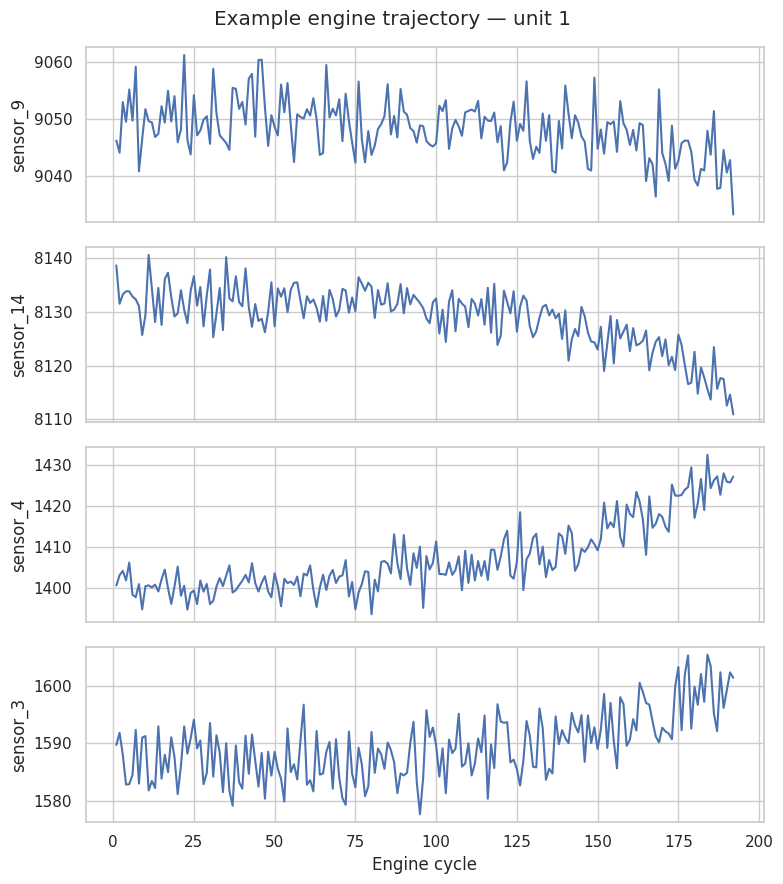

In [6]:
example_engine = train_df["unit_number"].iloc[0]
example = train_df[train_df["unit_number"] == example_engine]

sensor_cols = [f"sensor_{i}" for i in range(1, 22)]

# Select a few sensors with visible variation for a compact plot.
sensor_std = train_df[sensor_cols].std().sort_values(ascending=False)
example_sensors = sensor_std.head(4).index.tolist()

fig, axes = plt.subplots(
    len(example_sensors),
    1,
    figsize=(8, 9),
    sharex=True
)

for ax, sensor in zip(axes, example_sensors):
    ax.plot(
        example["time_cycles"],
        example[sensor]
    )
    ax.set_ylabel(sensor)

axes[-1].set_xlabel("Engine cycle")
fig.suptitle(f"Example engine trajectory — unit {example_engine}")
plt.tight_layout()
plt.show()


## 6. Select useful sensor features

Some sensor channels are constant or nearly constant in FD001. Including such columns adds noise without giving the model useful information.

I remove sensors with zero variance and keep the operational settings and time-based information.


In [7]:
feature_candidates = (
    ["time_cycles", "setting_1", "setting_2", "setting_3"]
    + sensor_cols
)

feature_std = train_df[feature_candidates].std()

constant_features = feature_std[
    feature_std == 0
].index.tolist()

print("Constant features removed:", constant_features)

feature_cols = [
    col for col in feature_candidates
    if col not in constant_features
]

print("Features kept:", len(feature_cols))
print(feature_cols)


Constant features removed: ['setting_3', 'sensor_18', 'sensor_19']
Features kept: 22
['time_cycles', 'setting_1', 'setting_2', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_20', 'sensor_21']


## 7. Create a leakage-safe validation strategy

A normal random row-level split is not appropriate here because rows from the same engine are strongly related over time.

Instead, engines are split as groups. No engine appears in both training and validation.

For a more realistic validation setup, I create one pseudo-test observation per validation engine by hiding its final part of the trajectory. The model then predicts the RUL at that artificial cutoff.


In [8]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

train_idx, valid_idx = next(
    splitter.split(
        train_df,
        groups=train_df["unit_number"]
    )
)

model_train = train_df.iloc[train_idx].copy()
validation_pool = train_df.iloc[valid_idx].copy()

print("Training engines:", model_train["unit_number"].nunique())
print("Validation engines:", validation_pool["unit_number"].nunique())


Training engines: 80
Validation engines: 20


In [9]:
# Build one pseudo-test point per validation engine.
# The cutoff is chosen 20 cycles before the engine's final cycle
# when the trajectory is long enough.

validation_rows = []

for unit_id, group in validation_pool.groupby("unit_number"):
    group = group.sort_values("time_cycles").reset_index(drop=True)

    if len(group) <= 30:
        cutoff_index = max(0, len(group) - 10)
    else:
        cutoff_index = len(group) - 20

    row = group.iloc[cutoff_index].copy()
    row["validation_RUL"] = (
        group["time_cycles"].max()
        - row["time_cycles"]
    )
    validation_rows.append(row)

validation_df = pd.DataFrame(validation_rows)

print("Validation observations:", len(validation_df))
display(
    validation_df[
        ["unit_number", "time_cycles", "validation_RUL"]
    ].head()
)


Validation observations: 20


,unit_number,time_cycles,validation_RUL
172,1.0,173.0,19.0
249,5.0,250.0,19.0
220,11.0,221.0,19.0
143,13.0,144.0,19.0
138,19.0,139.0,19.0


## 8. Prepare training data

The model is trained on observations from the training engines only.

The validation points come from completely different engines, which makes the validation result much more meaningful for this time-series problem.


In [10]:
X_train = model_train[feature_cols]
y_train = model_train["RUL"]

X_valid = validation_df[feature_cols]
y_valid = validation_df["validation_RUL"]

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)


X_train: (16561, 22)
X_valid: (20, 22)


## 9. Train two regression models

I compare:

- **Random Forest Regressor** — a strong tree-based baseline that can model nonlinear relationships.
- **HistGradientBoosting Regressor** — a boosting model that is efficient on tabular data and provides a useful second perspective.

The goal is not to use the most complicated model possible. The comparison should show whether additional model complexity actually helps.


In [11]:
models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        min_samples_leaf=2
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=RANDOM_STATE
    )
}

validation_results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_valid)
    predictions = np.clip(predictions, 0, None)

    validation_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_valid, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_valid, predictions)
        ),
        "R2": r2_score(y_valid, predictions)
    })

validation_results = (
    pd.DataFrame(validation_results)
    .sort_values("RMSE")
)

display(validation_results)


,Model,MAE,RMSE,R2
0,Random Forest,6.252735,8.729682,0.0
1,HistGradientBoosting,6.930050,9.642351,0.0


## 10. Select the final model

RMSE is the primary metric because it is also the metric used by the Kaggle predictive-maintenance competition.

MAE is reported as a second metric because it is easier to interpret as an average absolute cycle error.


In [12]:
best_model_name = validation_results.iloc[0]["Model"]
best_model = models[best_model_name]

print("Selected model:", best_model_name)

best_valid_pred = best_model.predict(X_valid)
best_valid_pred = np.clip(best_valid_pred, 0, None)

print(
    "Validation MAE :",
    round(mean_absolute_error(y_valid, best_valid_pred), 2)
)
print(
    "Validation RMSE:",
    round(
        np.sqrt(
            mean_squared_error(
                y_valid,
                best_valid_pred
            )
        ),
        2
    )
)
print(
    "Validation R2  :",
    round(r2_score(y_valid, best_valid_pred), 3)
)


Selected model: Random Forest
Validation MAE : 6.25
Validation RMSE: 8.73
Validation R2  : 0.0


## 11. Validation: actual vs predicted RUL


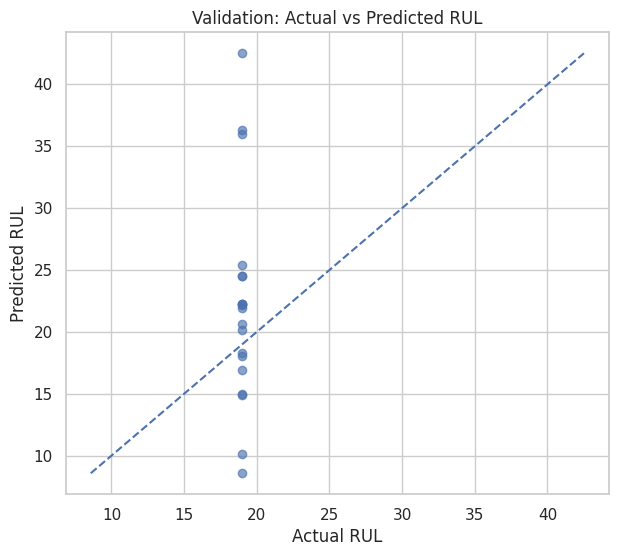

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    y_valid,
    best_valid_pred,
    alpha=0.65
)

lims = [
    min(y_valid.min(), best_valid_pred.min()),
    max(y_valid.max(), best_valid_pred.max())
]

ax.plot(
    lims,
    lims,
    linestyle="--"
)

ax.set_xlabel("Actual RUL")
ax.set_ylabel("Predicted RUL")
ax.set_title("Validation: Actual vs Predicted RUL")

plt.show()


## 12. Fit on all available training engines

After model selection, the final model is retrained using every training observation because the validation stage has already been used to choose the model.

The official test set remains untouched until this point.


In [14]:
final_model = models[best_model_name]
final_model.fit(
    train_df[feature_cols],
    train_df["RUL"]
)

print("Final model fitted on:", len(train_df), "training rows")


Final model fitted on: 20631 training rows


## 13. Evaluate on the official test scenario

The official test set stops before failure. Therefore, only the **last observed cycle of each test engine** is used for the final RUL prediction.

This matches the intended prediction scenario: estimate how many cycles remain after the last available observation.


In [15]:
last_test_rows = (
    test_df.sort_values(["unit_number", "time_cycles"])
    .groupby("unit_number")
    .tail(1)
    .sort_values("unit_number")
    .reset_index(drop=True)
)

test_predictions = final_model.predict(
    last_test_rows[feature_cols]
)

test_predictions = np.clip(
    test_predictions,
    0,
    None
)

official_results = pd.DataFrame({
    "unit_number": last_test_rows["unit_number"].values,
    "actual_RUL": true_rul["RUL"].values,
    "predicted_RUL": test_predictions
})

official_results["absolute_error"] = (
    official_results["actual_RUL"]
    - official_results["predicted_RUL"]
).abs()

display(official_results.head(10))


,unit_number,actual_RUL,predicted_RUL,absolute_error
0,1,112,171.967290,59.967290
1,2,98,155.419578,57.419578
2,3,69,55.450360,13.549640
3,4,82,74.767694,7.232306
4,5,91,104.272503,13.272503
5,6,93,92.568491,0.431509
6,7,91,112.859800,21.859800
7,8,95,69.332865,25.667135
8,9,111,145.571165,34.571165
9,10,96,118.519483,22.519483


In [16]:
official_mae = mean_absolute_error(
    official_results["actual_RUL"],
    official_results["predicted_RUL"]
)

official_rmse = np.sqrt(
    mean_squared_error(
        official_results["actual_RUL"],
        official_results["predicted_RUL"]
    )
)

official_r2 = r2_score(
    official_results["actual_RUL"],
    official_results["predicted_RUL"]
)

print("Official test MAE :", round(official_mae, 2))
print("Official test RMSE:", round(official_rmse, 2))
print("Official test R2  :", round(official_r2, 3))


Official test MAE : 19.83
Official test RMSE: 26.41
Official test R2  : 0.596


## 14. Official test error analysis


In [17]:
display(
    official_results
    .sort_values("absolute_error", ascending=False)
    .head(10)
)


,unit_number,actual_RUL,predicted_RUL,absolute_error
14,15,83,166.367980,83.367980
66,67,77,143.326512,66.326512
0,1,112,171.967290,59.967290
21,22,111,169.131574,58.131574
1,2,98,155.419578,57.419578
84,85,118,172.574985,54.574985
77,78,107,160.216483,53.216483
40,41,18,63.363587,45.363587
13,14,107,152.301931,45.301931
26,27,66,110.095553,44.095553


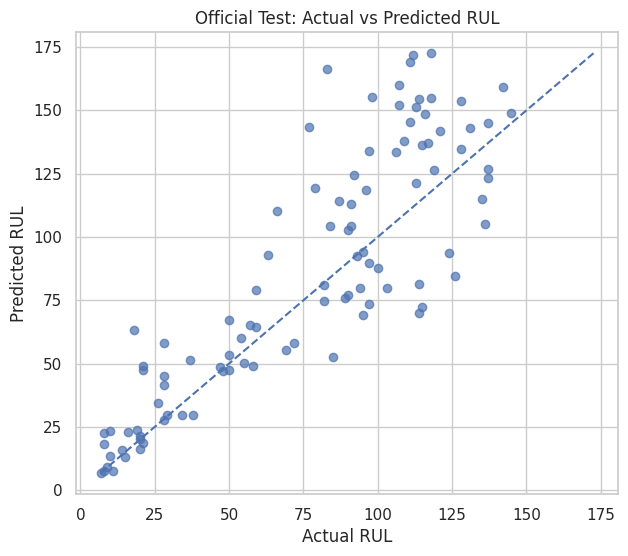

In [18]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    official_results["actual_RUL"],
    official_results["predicted_RUL"],
    alpha=0.7
)

lims = [
    min(
        official_results["actual_RUL"].min(),
        official_results["predicted_RUL"].min()
    ),
    max(
        official_results["actual_RUL"].max(),
        official_results["predicted_RUL"].max()
    )
]

ax.plot(lims, lims, linestyle="--")

ax.set_xlabel("Actual RUL")
ax.set_ylabel("Predicted RUL")
ax.set_title("Official Test: Actual vs Predicted RUL")

plt.show()


## 15. Validation vs official test performance

The validation score is used for model selection, while the official FD001 test set is the final evaluation scenario.

Comparing both helps quantify how well the validation setup reflects the official test distribution.


In [19]:
performance_comparison = pd.DataFrame([
    {
        "Scenario": "Validation",
        "MAE": mean_absolute_error(y_valid, best_valid_pred),
        "RMSE": np.sqrt(mean_squared_error(y_valid, best_valid_pred)),
        "R²": r2_score(y_valid, best_valid_pred)
    },
    {
        "Scenario": "Official Test",
        "MAE": official_mae,
        "RMSE": official_rmse,
        "R²": official_r2
    }
])

display(
    performance_comparison.style.format({
        "MAE": "{:.2f}",
        "RMSE": "{:.2f}",
        "R²": "{:.3f}"
    })
)


,Scenario,MAE,RMSE,R²
0,Validation,6.25,8.73,0.000
1,Official Test,19.83,26.41,0.596


## 16. Official test error distribution


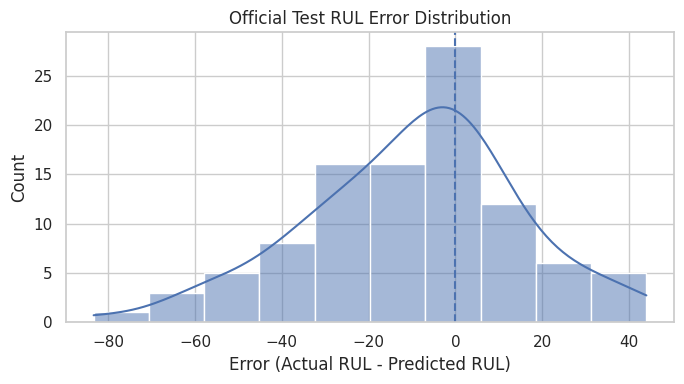

In [20]:
official_results["signed_error"] = (
    official_results["actual_RUL"]
    - official_results["predicted_RUL"]
)

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(
    official_results["signed_error"],
    kde=True,
    ax=ax
)
ax.axvline(0, linestyle="--")
ax.set_title("Official Test RUL Error Distribution")
ax.set_xlabel("Error (Actual RUL - Predicted RUL)")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()


## 17. Feature importance

For the Random Forest model, feature importance gives a useful indication of which variables contributed most to the predictions.

If HistGradientBoosting is selected, this section is skipped because that model does not expose the same `feature_importances_` attribute.


,importance
time_cycles,0.5544
sensor_11,0.1539
sensor_9,0.0414
sensor_12,0.0290
sensor_4,0.0268
sensor_14,0.0249
sensor_7,0.0224
sensor_15,0.0215
sensor_21,0.0194
sensor_3,0.0179


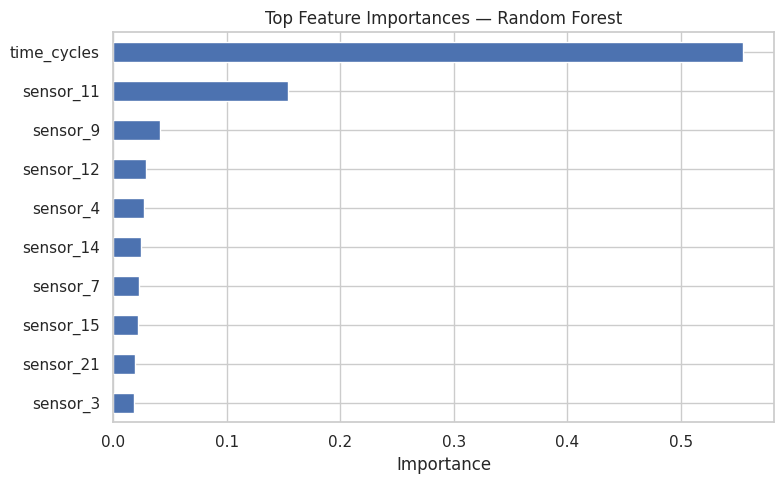

In [21]:
if hasattr(final_model, "feature_importances_"):
    importance = (
        pd.Series(
            final_model.feature_importances_,
            index=feature_cols
        )
        .sort_values(ascending=False)
    )

    display(
        importance.head(15)
        .rename("importance")
        .to_frame()
        .style.format("{:.4f}")
    )

    importance.head(10).sort_values().plot(
        kind="barh",
        figsize=(8, 5)
    )

    plt.title(f"Top Feature Importances — {best_model_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    print(
        f"Feature importance is not displayed for {best_model_name} "
        "because this estimator does not expose feature_importances_."
    )


## 17. Portfolio-ready results

### Project
**Predictive Maintenance — Remaining Useful Life (RUL) Prediction**

### Dataset
NASA C-MAPSS — FD001

### Final model
The model selected from the engine-level validation setup.

### Key evaluation
- Validation performance is used for model selection.
- Official FD001 test performance is reported separately.
- RUL is measured in remaining engine cycles.

### Strong portfolio visuals
1. Engine degradation / sensor trajectory
2. Validation model comparison
3. Official test actual vs predicted RUL
4. Validation vs official test metrics
5. Feature importance
6. Official test error distribution


In [22]:
print("Predictive Maintenance — Final Summary")
print("=" * 55)
print(f"Selected model: {best_model_name}")
print(f"Validation RMSE: {mean_squared_error(y_valid, best_valid_pred) ** 0.5:.2f}")
print(f"Official Test MAE: {official_mae:.2f}")
print(f"Official Test RMSE: {official_rmse:.2f}")
print(f"Official Test R²: {official_r2:.3f}")

if "importance" in globals():
    print(f"Top feature by model importance: {importance.index[0]}")


Predictive Maintenance — Final Summary
Selected model: Random Forest
Validation RMSE: 8.73
Official Test MAE: 19.83
Official Test RMSE: 26.41
Official Test R²: 0.596
Top feature by model importance: time_cycles


## 19. Final takeaway

This project demonstrates a practical predictive-maintenance workflow:

1. Load real engine degradation time series.
2. Build the RUL target from run-to-failure training data.
3. Remove uninformative sensor channels.
4. Split by engine rather than randomly splitting rows.
5. Create a pseudo-test validation setup.
6. Compare two regression models.
7. Select the model using RMSE.
8. Retrain on all training engines.
9. Predict RUL for the final observed cycle of each test engine.
10. Evaluate against the official RUL values.

### Business interpretation

In a real maintenance system, the predicted RUL could support decisions such as inspection scheduling, maintenance planning, and prioritizing assets that are approaching failure.

### Limitations

This is a simulated turbofan-engine degradation dataset, not live aircraft data. The results should therefore be presented as a demonstration of a predictive-maintenance ML workflow, not as a production aviation safety system.

The project focuses on FD001 to keep the scope controlled. The full C-MAPSS collection also contains FD002–FD004 with different operating conditions and fault modes.


## 20. Project notes

**Problem type:** Predictive maintenance / RUL regression

**Dataset:** NASA C-MAPSS, FD001

**Target:** Remaining Useful Life (cycles)

**Primary metric:** RMSE

**Models:** Random Forest Regressor and HistGradientBoosting Regressor

**Validation principle:** Engine-level split with a pseudo-test cutoff to reduce time leakage

**Final evaluation:** Official FD001 test trajectories and their provided RUL values
